## EN3150 Assignment 03: Resource-Constrained CNN for Image Classification

### Animals-10 Dataset

**Objective:** Develop and evaluate convolutional neural networks for classifying animal images.

The dataset contains ten animal classes. All images will be resized to 64 × 64 pixels and represented using RGB channels.

The dataset will be divided into three subsets:

- Training set: 70%
- Validation set: 15%
- Testing set: 15%

The same dataset split will be used for all models to ensure a fair comparison.

**Framework:** TensorFlow and Keras

**Dataset:** Animals-10

In [8]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2 as cv

from pathlib import Path
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("OpenCV version:", cv.__version__)
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

OpenCV version: 5.0.0
TensorFlow version: 2.22.0-rc0
NumPy version: 2.5.3
GPU devices: []


In [38]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "data" / "raw-img"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Dataset directory exists:", DATASET_DIR.exists())

Project directory: e:\SEM 5\pattern\Assignment 03\EN3150_Animal_Classification_CNN
Dataset directory: e:\SEM 5\pattern\Assignment 03\EN3150_Animal_Classification_CNN\data\raw-img
Dataset directory exists: True


In [39]:
class_folders = sorted(
    folder for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
)

print("Number of classes:", len(class_folders))
print("\nAnimal classes:")

for folder in class_folders:
    print(folder.name)

Number of classes: 10

Animal classes:
Butterfly
Cat
Chicken
Cow
Dog
Elephant
Horse
Sheep
Spider
Squirrel


In [40]:
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_counts = {}

for folder in class_folders:
    count = 0

    for file in folder.iterdir():
        if file.is_file() and file.suffix.lower() in valid_extensions:
            image = cv.imread(str(file))

            if image is not None:
                count += 1

    class_counts[folder.name] = count

class_counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Animal Class", "Number of Images"]
)

display(class_counts_df)

print("Total valid images:", sum(class_counts.values()))

,Animal Class,Number of Images
0,Butterfly,2112
1,Cat,1668
2,Chicken,3098
3,Cow,1866
4,Dog,4863
5,Elephant,1446
6,Horse,2623
7,Sheep,1820
8,Spider,4821
9,Squirrel,1862


Total valid images: 26179


## Stratified Dataset Splitting

The dataset contains an unequal number of images in each animal class. To maintain similar class proportions in the training, validation, and testing sets, stratified sampling is used.

The dataset is divided into 70% training, 15% validation, and 15% testing data. The same split will be used for all CNN models to ensure a fair comparison. The original class distribution is retained without removing or duplicating images.

In [41]:
from sklearn.model_selection import train_test_split

# Map class names to consistent integer labels
class_names = sorted(
    folder.name for folder in class_folders
)

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

# Collect valid image paths and their labels
image_paths = []
image_labels = []

for folder in class_folders:
    label = class_to_index[folder.name]

    for file in folder.iterdir():
        if file.is_file() and file.suffix.lower() in valid_extensions:
            image = cv.imread(str(file))

            if image is not None:
                image_paths.append(str(file.resolve()))
                image_labels.append(label)

image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Total valid images:", len(image_paths))
print("Number of classes:", len(class_names))
print("Class mapping:", class_to_index)

Total valid images: 26179
Number of classes: 10
Class mapping: {'Butterfly': 0, 'Cat': 1, 'Chicken': 2, 'Cow': 3, 'Dog': 4, 'Elephant': 5, 'Horse': 6, 'Sheep': 7, 'Spider': 8, 'Squirrel': 9}


In [42]:
RANDOM_SEED = 42

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=image_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

Training images: 18325
Validation images: 3927
Test images: 3927
Total: 26179


## Image Preprocessing for Model 01

All images are resized to 64 × 64 pixels and converted from BGR to RGB using OpenCV. Pixel values are normalized from the range [0, 255] to [0, 1].

The images are loaded in batches to reduce memory usage during training. The same preprocessing procedure is applied to the training, validation, and test sets.

In [55]:
#Define image preprocessing
IMG_SIZE = 64
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

def load_image(image_path, label):
    image = cv.imread(image_path)

    if image is None:
        raise ValueError(f"Could not load image: {image_path}")

    image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
    image = cv.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv.INTER_AREA
    )

    image = image.astype(np.float32) / 255.0

    return image, label

In [56]:
def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels.astype(np.int32))
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(paths), 5000),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda path, label: tf.numpy_function(
            load_image,
            [path, label],
            [tf.float32, tf.int32]
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.map(
        lambda image, label: (
            tf.ensure_shape(image, (IMG_SIZE, IMG_SIZE, 3)),
            tf.ensure_shape(label, ())
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 573
Validation batches: 123
Testing batches: 123


In [57]:
#Inspect one batch
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


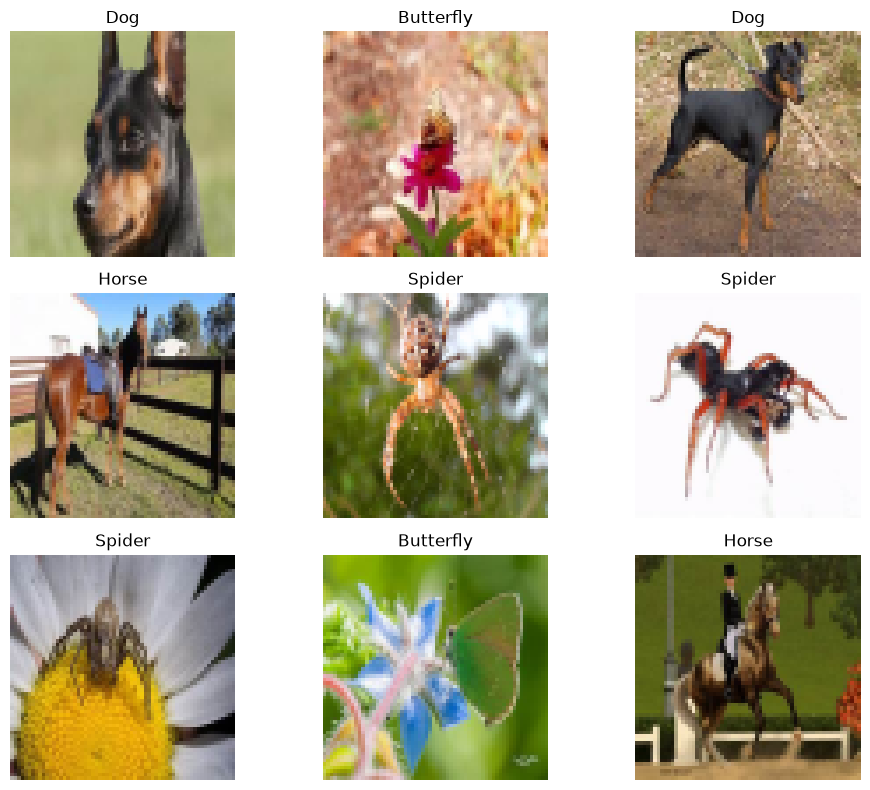

In [58]:
#Display preprocessed images
plt.figure(figsize=(10, 8))

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy())
    label_index = int(labels[i].numpy())

    plt.title(class_names[label_index])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [59]:
#Define the model
model_a = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Convolutional block 1
    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(NUM_CLASSES)
])

model_a.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,442 (1.09 MB)

 Trainable params: 286,442 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [60]:
total_params = model_a.count_params()

trainable_params = sum(
    np.prod(weight.shape)
    for weight in model_a.trainable_weights
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 286442
Trainable parameters: 286442


In [61]:
# Compile Model A
model_a.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("Model A compiled successfully.")

Model A compiled successfully.


### Model Training

The compiled CNN is trained using the training dataset for 10 epochs. The validation dataset is used to monitor the model's performance on unseen images after each epoch. The training time is also recorded to evaluate the computational cost of the model.

In [62]:
import time

start_time = time.time()

history_a = model_a.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=1
)

training_time_a = time.time() - start_time

print(f"Total training time: {training_time_a / 60:.2f} minutes")

Epoch 1/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.3869 - loss: 1.7393 - val_accuracy: 0.4958 - val_loss: 1.4974
Epoch 2/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step - accuracy: 0.5438 - loss: 1.3296 - val_accuracy: 0.5567 - val_loss: 1.3073
Epoch 3/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 17s 29ms/step - accuracy: 0.6051 - loss: 1.1556 - val_accuracy: 0.5730 - val_loss: 1.2435
Epoch 4/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.6539 - loss: 1.0278 - val_accuracy: 0.6071 - val_loss: 1.1718
Epoch 5/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.6934 - loss: 0.9048 - val_accuracy: 0.6300 - val_loss: 1.1104
Epoch 6/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.7283 - loss: 0.8100 - val_accuracy: 0.6404 - val_loss: 1.1017
Epoch 7/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step - accuracy: 0.7561 - loss: 0.7165 - val_accuracy: 0.6267 - val_loss: 1.1686
Epoch 8/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.7856 - loss: 0.6295 - 

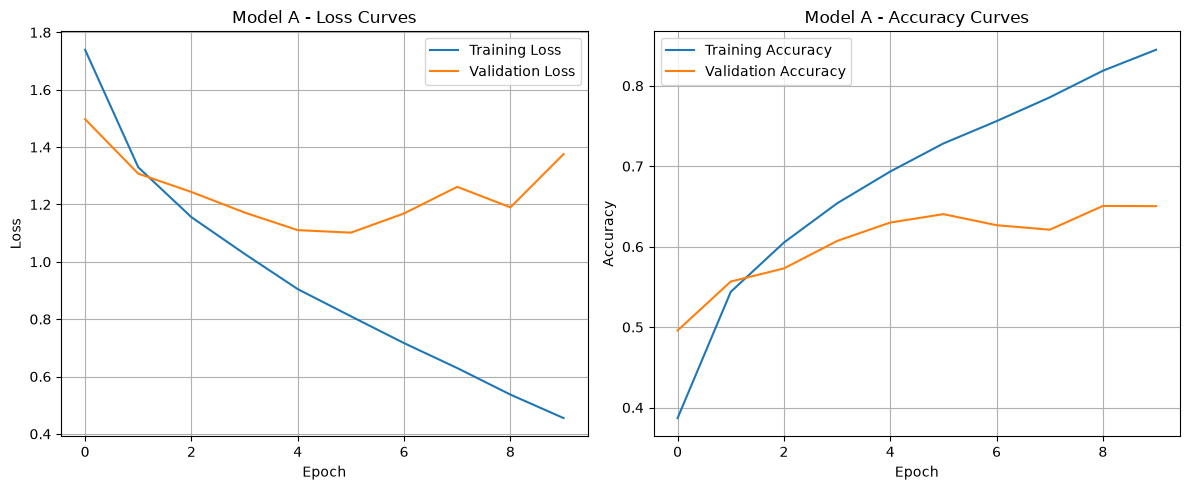

In [63]:
plt.figure(figsize=(12, 5))

# Loss curves
plt.subplot(1, 2, 1)
plt.plot(history_a.history["loss"], label="Training Loss")
plt.plot(history_a.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A - Loss Curves")
plt.legend()
plt.grid(True)

# Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(history_a.history["accuracy"], label="Training Accuracy")
plt.plot(history_a.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A - Accuracy Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Model A Improvement: Dropout Regularization

The initial training results indicate overfitting, as the training loss decreases while the validation loss begins to increase. Dropout regularization is introduced into the classification head to reduce overfitting and improve generalization to unseen images. The model is trained with the same training and validation datasets to allow a fair comparison.

In [64]:
model_a_dropout = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Convolutional block 1
    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head with dropout
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES)
])

model_a_dropout.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)              │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,442 (1.09 MB)

 Trainable params: 286,442 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model_a_dropout.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("Improved Model A compiled successfully.")

Improved Model A compiled successfully.


### Training the Improved Model A

The improved CNN is trained using dropout regularization with a dropout rate of 0.5. The same training and validation datasets are used to compare its performance with the original CNN. Training and validation accuracy, loss, and total training time are recorded.

In [32]:
import time

start_time = time.time()

history_a_dropout = model_a_dropout.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=1
)

training_time_a_dropout = time.time() - start_time

print(
    f"Improved Model A training time: "
    f"{training_time_a_dropout / 60:.2f} minutes"
)

Epoch 1/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.2499 - loss: 2.0646 - val_accuracy: 0.3501 - val_loss: 1.7895
Epoch 2/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.3708 - loss: 1.7831 - val_accuracy: 0.4663 - val_loss: 1.5472
Epoch 3/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.4367 - loss: 1.6090 - val_accuracy: 0.5284 - val_loss: 1.4363
Epoch 4/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.4829 - loss: 1.4895 - val_accuracy: 0.5600 - val_loss: 1.3122
Epoch 5/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.5061 - loss: 1.4125 - val_accuracy: 0.5399 - val_loss: 1.3648
Epoch 6/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.5259 - loss: 1.3498 - val_accuracy: 0.5806 - val_loss: 1.2592
Epoch 7/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.5459 - loss: 1.2887 - val_accuracy: 0.5778 - val_loss: 1.2361
Epoch 8/10
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.5591 - loss: 1.2478 - 

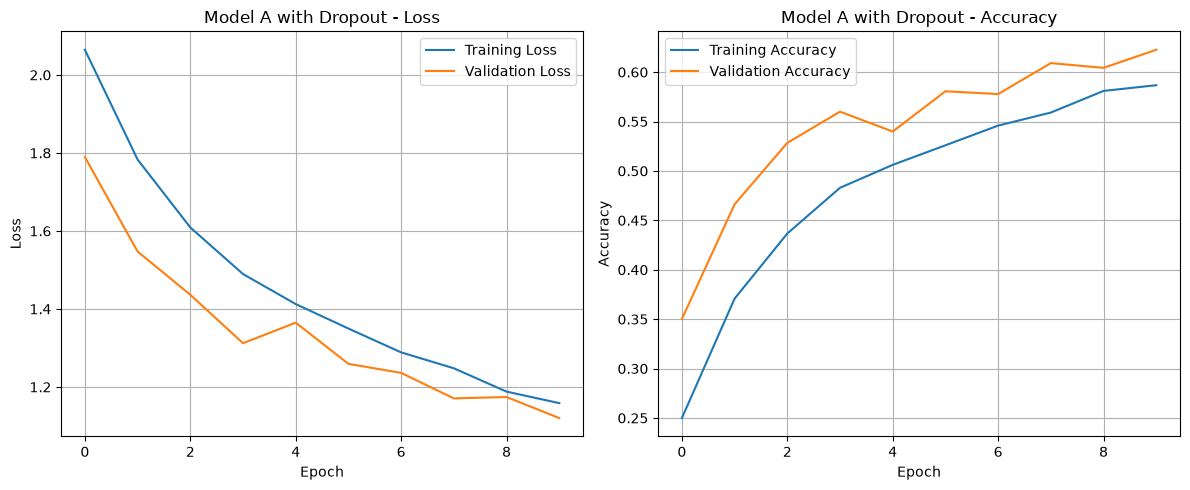

In [33]:
plt.figure(figsize=(12, 5))

# Loss curves
plt.subplot(1, 2, 1)
plt.plot(history_a_dropout.history["loss"], label="Training Loss")
plt.plot(history_a_dropout.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A with Dropout - Loss")
plt.legend()
plt.grid(True)

# Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(history_a_dropout.history["accuracy"], label="Training Accuracy")
plt.plot(history_a_dropout.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A with Dropout - Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [34]:
test_loss_a, test_accuracy_a = model_a.evaluate(test_ds, verbose=1)

test_loss_a_dropout, test_accuracy_a_dropout = (
    model_a_dropout.evaluate(test_ds, verbose=1)
)

print("\nTest Results")
print("-" * 40)
print(f"Original Model A - Test Loss: {test_loss_a:.4f}")
print(f"Original Model A - Test Accuracy: {test_accuracy_a * 100:.2f}%")
print()
print(f"Dropout Model A - Test Loss: {test_loss_a_dropout:.4f}")
print(f"Dropout Model A - Test Accuracy: {test_accuracy_a_dropout * 100:.2f}%")

123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6537 - loss: 1.1948
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6366 - loss: 1.1125

Test Results
----------------------------------------
Original Model A - Test Loss: 1.1948
Original Model A - Test Accuracy: 65.37%

Dropout Model A - Test Loss: 1.1125
Dropout Model A - Test Accuracy: 63.66%


In [65]:
model_a_final = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Block 1
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    # Block 2
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    # Block 3
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES)
])

model_a_final.summary()

print("Trainable parameters:",
      sum(np.prod(w.shape) for w in model_a_final.trainable_weights))

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_22 (Conv2D)              │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,394 (110.91 KB)

 Trainable params: 28,394 (110.91 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 28394


In [66]:
model_a_final.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("Model A compiled successfully.")

Model A compiled successfully.


In [67]:
import time
import tensorflow as tf

start_time = time.time()

history_a_final = model_a_final.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        )
    ],
    verbose=1
)

training_time_a_final = time.time() - start_time

print(f"\nTotal training time: {training_time_a_final / 60:.2f} minutes")
print(f"Average time per epoch: {training_time_a_final / len(history_a_final.epoch):.2f} seconds")

Epoch 1/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.2230 - loss: 2.1493 - val_accuracy: 0.2776 - val_loss: 2.0652 - learning_rate: 0.0010
Epoch 2/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.2948 - loss: 2.0001 - val_accuracy: 0.3308 - val_loss: 1.9028 - learning_rate: 0.0010
Epoch 3/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.3467 - loss: 1.8367 - val_accuracy: 0.3568 - val_loss: 1.8278 - learning_rate: 0.0010
Epoch 4/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.3865 - loss: 1.7253 - val_accuracy: 0.4248 - val_loss: 1.6402 - learning_rate: 0.0010
Epoch 5/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.4190 - loss: 1.6364 - val_accuracy: 0.4306 - val_loss: 1.6187 - learning_rate: 0.0010
Epoch 6/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.4369 - loss: 1.5852 - val_accuracy: 0.4507 - val_loss: 1.5841 - learning_rate: 0.0010
Epoch 7/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.4559 - l

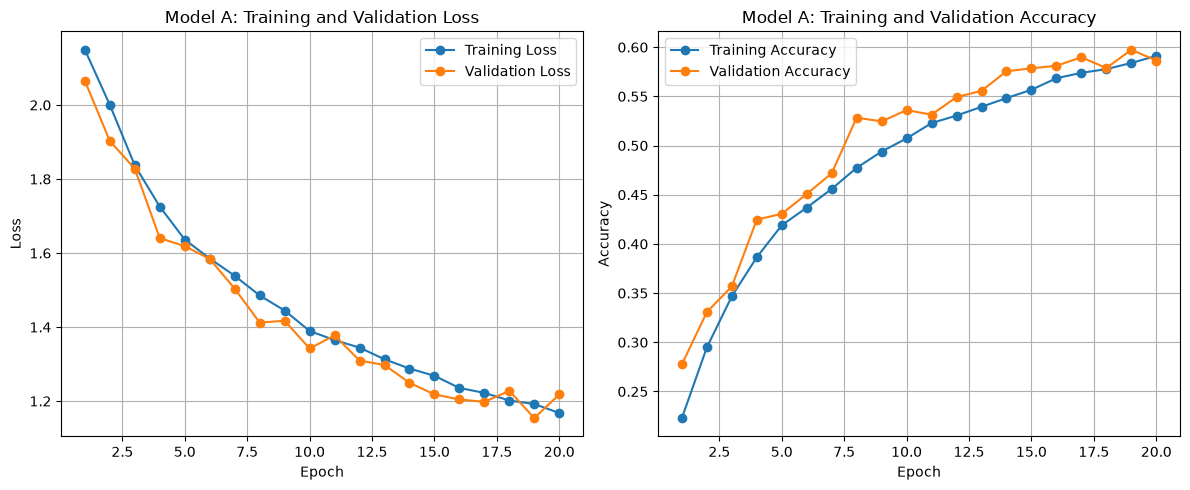

Epochs completed: 20
Best validation accuracy: 59.74%
Lowest validation loss: 1.1540


In [68]:
import matplotlib.pyplot as plt

epochs = range(1, len(history_a_final.history["loss"]) + 1)

plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(epochs, history_a_final.history["loss"], marker="o",
         label="Training Loss")
plt.plot(epochs, history_a_final.history["val_loss"], marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A: Training and Validation Loss")
plt.legend()
plt.grid(True)

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(epochs, history_a_final.history["accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(epochs, history_a_final.history["val_accuracy"], marker="o",
         label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A: Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Epochs completed:", len(history_a_final.epoch))
print(f"Best validation accuracy: "
      f"{max(history_a_final.history['val_accuracy']) * 100:.2f}%")
print(f"Lowest validation loss: "
      f"{min(history_a_final.history['val_loss']):.4f}")

In [72]:

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model_a_large = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Block 1
    layers.Conv2D(24, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(48, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(96, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(440, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES)
])

model_a_large.summary()

trainable_params = sum(
    np.prod(w.shape) for w in model_a_large.trainable_weights
)

print(f"Trainable parameters: {trainable_params:,}")


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_34 (Conv2D)              │ (None, 64, 64, 24)     │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 32, 32, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 32, 32, 48)     │        10,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 16, 16, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 16, 16, 96)     │        41,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 8, 8, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 96)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 440)            │        42,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 440)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         4,410 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,746 (389.63 KB)

 Trainable params: 99,746 (389.63 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 99,746


In [73]:

model_a_large.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("Model A compiled successfully.")


Model A compiled successfully.


In [74]:

import time

start_time = time.time()

history_a_large = model_a_large.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        )
    ],
    verbose=1
)

training_time_a_large = time.time() - start_time

print(f"Total training time: {training_time_a_large / 60:.2f} minutes")
print(
    f"Average time per epoch: "
    f"{training_time_a_large / len(history_a_large.epoch):.2f} seconds"
)


Epoch 1/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.2378 - loss: 2.1171 - val_accuracy: 0.3175 - val_loss: 1.9341 - learning_rate: 0.0010
Epoch 2/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.3493 - loss: 1.8269 - val_accuracy: 0.3804 - val_loss: 1.7529 - learning_rate: 0.0010
Epoch 3/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.4103 - loss: 1.6661 - val_accuracy: 0.4283 - val_loss: 1.6501 - learning_rate: 0.0010
Epoch 4/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.4524 - loss: 1.5508 - val_accuracy: 0.4719 - val_loss: 1.5026 - learning_rate: 0.0010
Epoch 5/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.4921 - loss: 1.4337 - val_accuracy: 0.5241 - val_loss: 1.3661 - learning_rate: 0.0010
Epoch 6/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.5210 - loss: 1.3511 - val_accuracy: 0.5075 - val_loss: 1.4230 - learning_rate: 0.0010
Epoch 7/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.5421 - l

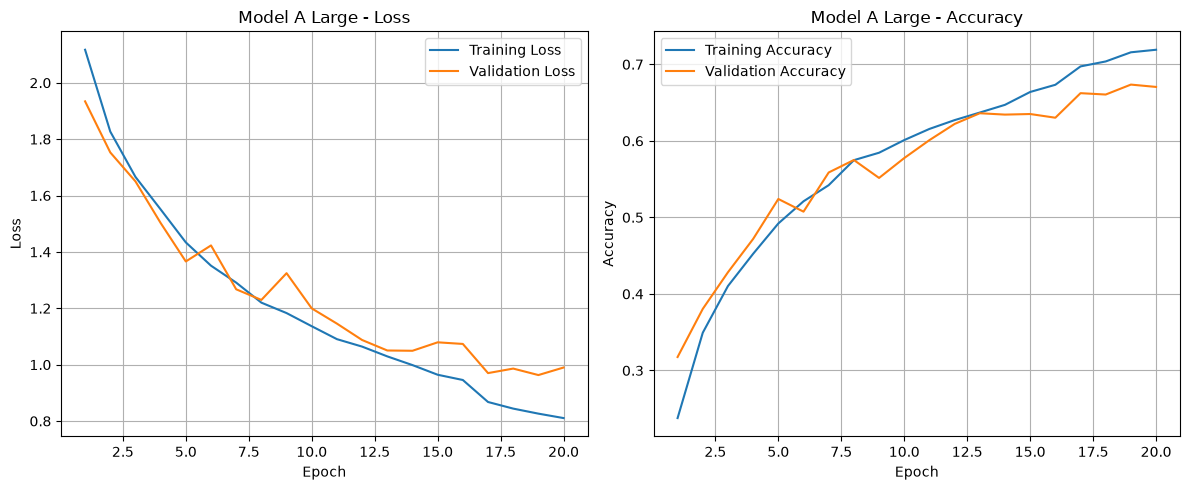

Best validation accuracy: 67.35%
Lowest validation loss: 0.9632


In [75]:

import matplotlib.pyplot as plt

epochs = range(1, len(history_a_large.history["loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history_a_large.history["loss"], label="Training Loss")
plt.plot(epochs, history_a_large.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A Large - Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history_a_large.history["accuracy"], label="Training Accuracy")
plt.plot(epochs, history_a_large.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A Large - Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(
    f"Best validation accuracy: "
    f"{max(history_a_large.history['val_accuracy']) * 100:.2f}%"
)
print(
    f"Lowest validation loss: "
    f"{min(history_a_large.history['val_loss']):.4f}"
)


In [76]:

test_loss_a_large, test_accuracy_a_large = model_a_large.evaluate(
    test_ds, verbose=1
)

print(f"Test Loss: {test_loss_a_large:.4f}")
print(f"Test Accuracy: {test_accuracy_a_large * 100:.2f}%")


123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.6723 - loss: 0.9494
Test Loss: 0.9494
Test Accuracy: 67.23%


In [77]:
final_train_acc = history_a_large.history["accuracy"][-1]
final_val_acc = history_a_large.history["val_accuracy"][-1]
best_val_acc = max(history_a_large.history["val_accuracy"])

print(f"Final training accuracy: {final_train_acc * 100:.2f}%")
print(f"Final validation accuracy: {final_val_acc * 100:.2f}%")
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")
print(
    f"Train-validation gap: "
    f"{(final_train_acc - final_val_acc) * 100:.2f} percentage points"
)

Final training accuracy: 71.91%
Final validation accuracy: 67.05%
Best validation accuracy: 67.35%
Train-validation gap: 4.86 percentage points


In [78]:

model_a_v2 = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Block 1
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Block 2
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Block 3
    layers.Conv2D(96, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(96, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES)
])

model_a_v2.summary()

print(
    "Trainable parameters:",
    sum(np.prod(w.shape) for w in model_a_v2.trainable_weights)
)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_37 (Conv2D)              │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 16, 16, 96)     │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 16, 16, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 16, 16, 96)     │        82,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 16, 16, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 16, 16, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 8, 8, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 96)             │             

 Total params: 232,554 (908.41 KB)

 Trainable params: 231,786 (905.41 KB)

 Non-trainable params: 768 (3.00 KB)

Trainable parameters: 231786


In [ ]:
model_a_dropout.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("Improved Model A compiled successfully.")

Improved Model A compiled successfully.


In [79]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import time
import matplotlib.pyplot as plt

IMG_SIZE = 64

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="data_augmentation")


In [80]:

model_a_augmented = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Data augmentation
    data_augmentation,

    # Block 1
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Block 2
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Block 3
    layers.Conv2D(96, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(96, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES)
])

model_a_augmented.summary()

trainable_params = sum(
    np.prod(w.shape) for w in model_a_augmented.trainable_weights
)

print(f"Trainable parameters: {trainable_params:,}")


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_38 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 16, 16, 96)     │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 16, 16, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 16, 16, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 16, 16, 96)     │        82,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 16, 16, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 16, 16, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_39 (MaxPooling2D) │ (None, 8, 8, 96)       │             

 Total params: 232,554 (908.41 KB)

 Trainable params: 231,786 (905.41 KB)

 Non-trainable params: 768 (3.00 KB)

Trainable parameters: 231,786


In [81]:

model_a_augmented.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("Improved Model A compiled successfully.")


Improved Model A compiled successfully.


In [82]:

start_time = time.time()

history_a_augmented = model_a_augmented.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        )
    ],
    verbose=1
)

training_time_a_augmented = time.time() - start_time

print(f"Total training time: {training_time_a_augmented / 60:.2f} minutes")
print(
    f"Average time per epoch: "
    f"{training_time_a_augmented / len(history_a_augmented.epoch):.2f} seconds"
)
print(
    f"Best validation accuracy: "
    f"{max(history_a_augmented.history['val_accuracy']) * 100:.2f}%"
)


Epoch 1/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 100s 171ms/step - accuracy: 0.3353 - loss: 1.8701 - val_accuracy: 0.2014 - val_loss: 2.7290 - learning_rate: 0.0010
Epoch 2/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 99s 173ms/step - accuracy: 0.4637 - loss: 1.5430 - val_accuracy: 0.4270 - val_loss: 1.6954 - learning_rate: 0.0010
Epoch 3/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 101s 176ms/step - accuracy: 0.5333 - loss: 1.3480 - val_accuracy: 0.4204 - val_loss: 1.8825 - learning_rate: 0.0010
Epoch 4/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.5854 - loss: 1.2116
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
573/573 ━━━━━━━━━━━━━━━━━━━━ 101s 176ms/step - accuracy: 0.5854 - loss: 1.2116 - val_accuracy: 0.3285 - val_loss: 2.3388 - learning_rate: 0.0010
Epoch 5/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 101s 177ms/step - accuracy: 0.6415 - loss: 1.0509 - val_accuracy: 0.5745 - val_loss: 1.2640 - learning_rate: 5.0000e-04
Epoch 6/20
573/573 ━━━━━━━━━━━━━━━━━━━━ 102s 178ms/step - accura

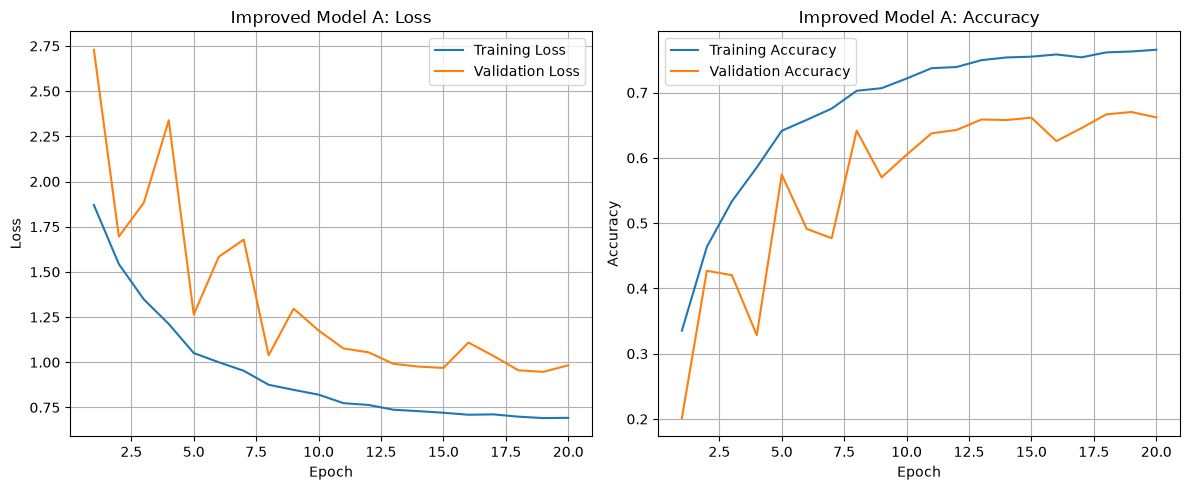

In [83]:

epochs = range(1, len(history_a_augmented.history["loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history_a_augmented.history["loss"], label="Training Loss")
plt.plot(epochs, history_a_augmented.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved Model A: Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history_a_augmented.history["accuracy"], label="Training Accuracy")
plt.plot(epochs, history_a_augmented.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved Model A: Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [84]:

test_loss_a_augmented, test_accuracy_a_augmented = (
    model_a_augmented.evaluate(test_ds, verbose=1)
)

print(f"Test Loss: {test_loss_a_augmented:.4f}")
print(f"Test Accuracy: {test_accuracy_a_augmented * 100:.2f}%")


123/123 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.6853 - loss: 0.9246
Test Loss: 0.9246
Test Accuracy: 68.53%


Best epoch: 19
Training accuracy at best epoch: 76.29%
Best validation accuracy: 67.02%
Validation loss at best epoch: 0.9467


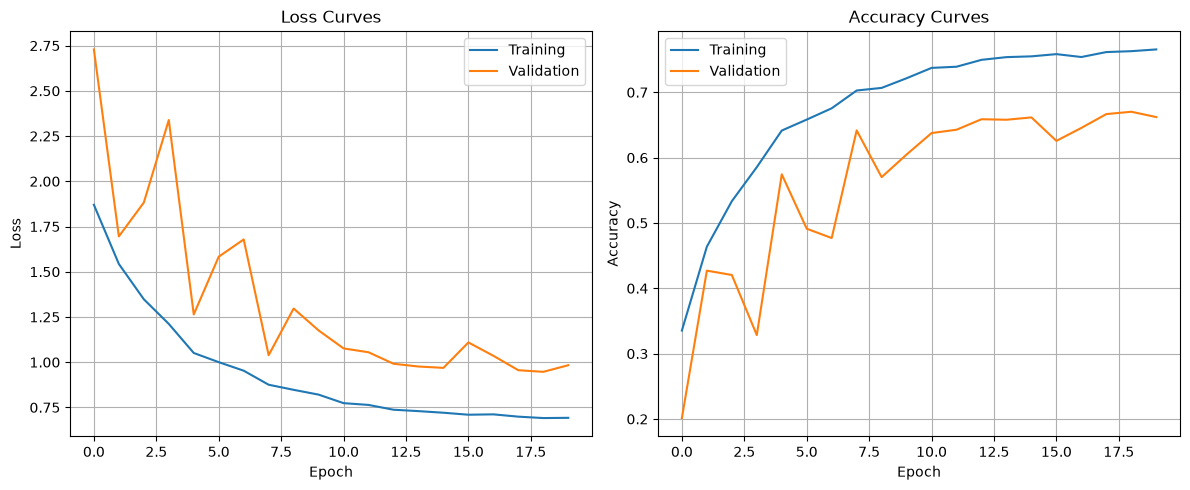

In [85]:

import numpy as np
import matplotlib.pyplot as plt

val_acc = history_a_augmented.history["val_accuracy"]
val_loss = history_a_augmented.history["val_loss"]
train_acc = history_a_augmented.history["accuracy"]

best_epoch = int(np.argmax(val_acc))

print(f"Best epoch: {best_epoch + 1}")
print(f"Training accuracy at best epoch: {train_acc[best_epoch] * 100:.2f}%")
print(f"Best validation accuracy: {val_acc[best_epoch] * 100:.2f}%")
print(f"Validation loss at best epoch: {val_loss[best_epoch]:.4f}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_a_augmented.history["loss"], label="Training")
plt.plot(val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curves")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_acc, label="Training")
plt.plot(val_acc, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
